In [2]:
!pip install numpy pandas matplotlib seaborn librosa scikit-learn tensorflow soundfile

  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl (350.8 MB)


In [3]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [5]:
import os

DATASET_PATH = r"C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24"

print(os.path.exists(DATASET_PATH))

True


In [6]:
emotion_mapping = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}

print(emotion_mapping)

{'01': 'neutral', '02': 'calm', '03': 'happy', '04': 'sad', '05': 'angry', '06': 'fearful', '07': 'disgust', '08': 'surprised'}


In [7]:
def extract_mfcc(file_path, n_mfcc=40, max_pad_len=130):
    try:
        audio, sample_rate = librosa.load(file_path, sr=22050)

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sample_rate,
            n_mfcc=n_mfcc
        )

        # Pad or truncate to fixed length
        if mfcc.shape[1] < max_pad_len:
            pad_width = max_pad_len - mfcc.shape[1]
            mfcc = np.pad(
                mfcc,
                pad_width=((0, 0), (0, pad_width)),
                mode="constant"
            )
        else:
            mfcc = mfcc[:, :max_pad_len]

        return mfcc

    except Exception as e:
        print("Error:", file_path, e)
        return None

In [8]:
X = []
y = []

for actor_folder in os.listdir(DATASET_PATH):

    actor_path = os.path.join(DATASET_PATH, actor_folder)

    if not os.path.isdir(actor_path):
        continue

    for file_name in os.listdir(actor_path):

        if file_name.endswith(".wav"):

            file_path = os.path.join(actor_path, file_name)

            # Extract emotion code
            emotion_code = file_name.split("-")[2]

            if emotion_code in emotion_mapping:

                mfcc = extract_mfcc(file_path)

                if mfcc is not None:
                    X.append(mfcc)
                    y.append(emotion_mapping[emotion_code])

print("Dataset loaded successfully!")
print("Number of audio files:", len(X))
print("Number of labels:", len(y))

Dataset loaded successfully!
Number of audio files: 1440
Number of labels: 1440


In [9]:
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1440, 40, 130)
y shape: (1440,)


calm         192
happy        192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
neutral       96
Name: count, dtype: int64


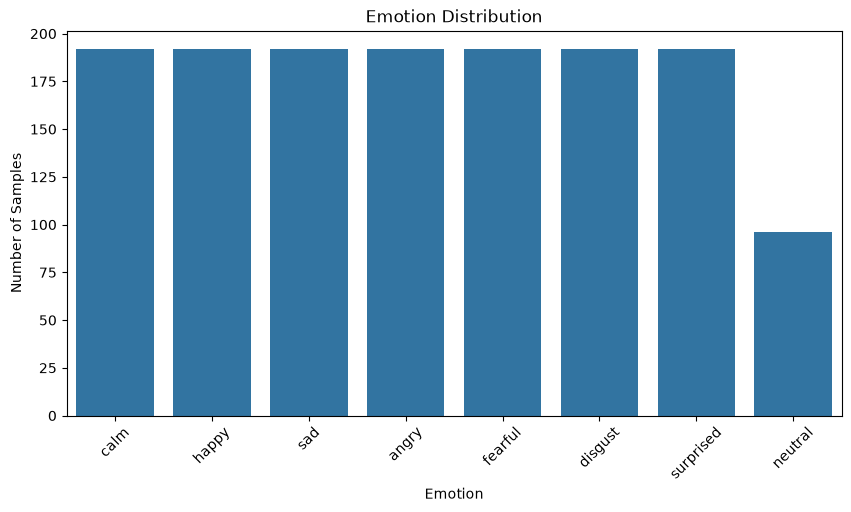

In [10]:
emotion_counts = pd.Series(y).value_counts()

print(emotion_counts)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=emotion_counts.index,
    y=emotion_counts.values
)

plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

In [11]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Emotion classes:")
print(label_encoder.classes_)

Emotion classes:
['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


In [12]:
num_classes = len(label_encoder.classes_)

y_categorical = to_categorical(
    y_encoded,
    num_classes=num_classes
)

print("Number of classes:", num_classes)
print("Encoded shape:", y_categorical.shape)

Number of classes: 8
Encoded shape: (1440, 8)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_categorical,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1152
Testing samples: 288


In [14]:
model = Sequential([
    
    LSTM(
        128,
        input_shape=(X_train.shape[1], X_train.shape[2]),
        return_sequences=True
    ),
    
    Dropout(0.3),
    
    LSTM(64),
    
    Dropout(0.3),
    
    Dense(64, activation="relu"),
    
    Dropout(0.3),
    
    Dense(num_classes, activation="softmax")
])

model.summary()

C:\Users\TRUPTI\Desktop\CodeAlpha\Emotion_Recognition\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ lstm (LSTM)                   │ (None, 40, 128)       │      132,608 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout (Dropout)             │ (None, 40, 128)       │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ lstm_1 (LSTM)                 │ (None, 64)            │       49,408 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_1 (Dropout)           │ (None, 64)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 64)            │        4,160 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_2 (Dropout)           │ (None, 64)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 8)             │          520 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 186,696 (729.28 KB)

 Trainable params: 186,696 (729.28 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [16]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    verbose=1
)

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.1618 - loss: 2.0702 - val_accuracy: 0.1991 - val_loss: 2.0306
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.2736 - loss: 1.9327 - val_accuracy: 0.2208 - val_loss: 1.9639
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.3713 - loss: 1.7471 - val_accuracy: 0.2597 - val_loss: 1.8247
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.4919 - loss: 1.5050 - val_accuracy: 0.3074 - val_loss: 1.7809
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.5950 - loss: 1.2130 - val_accuracy: 0.3074 - val_loss: 1.8378
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.6851 - loss: 0.9610 - val_accuracy: 0.2857 - val_loss: 2.0101
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.7383 - loss: 0.8231 - val_accuracy: 0.3463 - val_loss: 2.0296
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.7926 - loss: 0.6574 - val_accuracy: 0.2684 - v

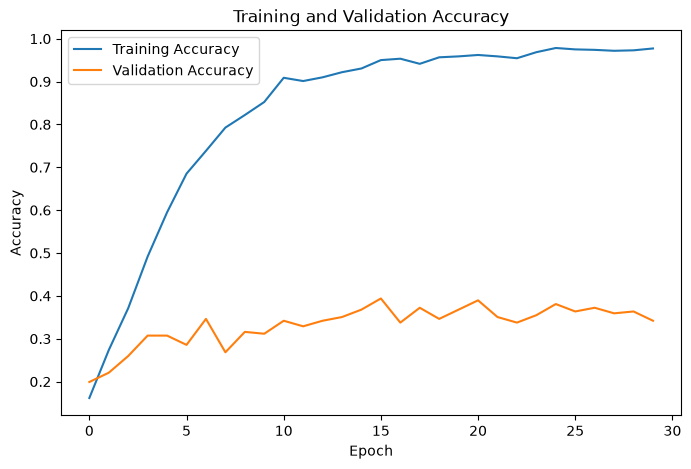

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

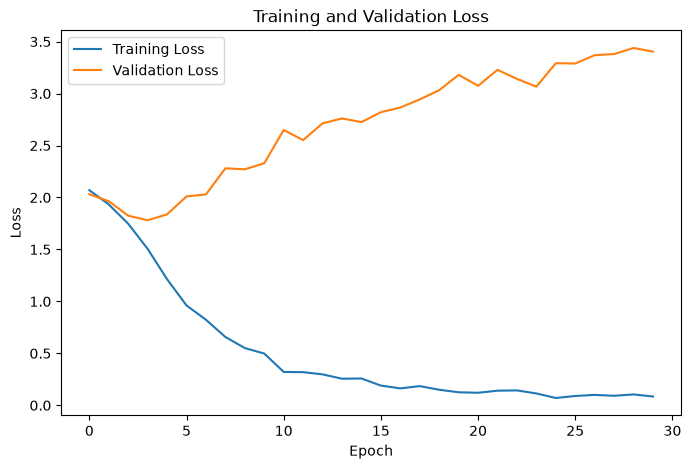

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [19]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 3.5048553943634033
Test Accuracy: 0.3333333432674408


In [20]:
y_pred_probability = model.predict(X_test)

y_pred = np.argmax(y_pred_probability, axis=1)
y_actual = np.argmax(y_test, axis=1)

print("Predictions generated successfully!")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Predictions generated successfully!


In [21]:
print(
    classification_report(
        y_actual,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

       angry       0.29      0.26      0.27        38
        calm       0.38      0.53      0.44        38
     disgust       0.33      0.32      0.32        38
     fearful       0.41      0.41      0.41        39
       happy       0.21      0.15      0.18        39
     neutral       0.26      0.32      0.29        19
         sad       0.35      0.29      0.32        38
   surprised       0.35      0.38      0.37        39

    accuracy                           0.33       288
   macro avg       0.32      0.33      0.32       288
weighted avg       0.33      0.33      0.33       288



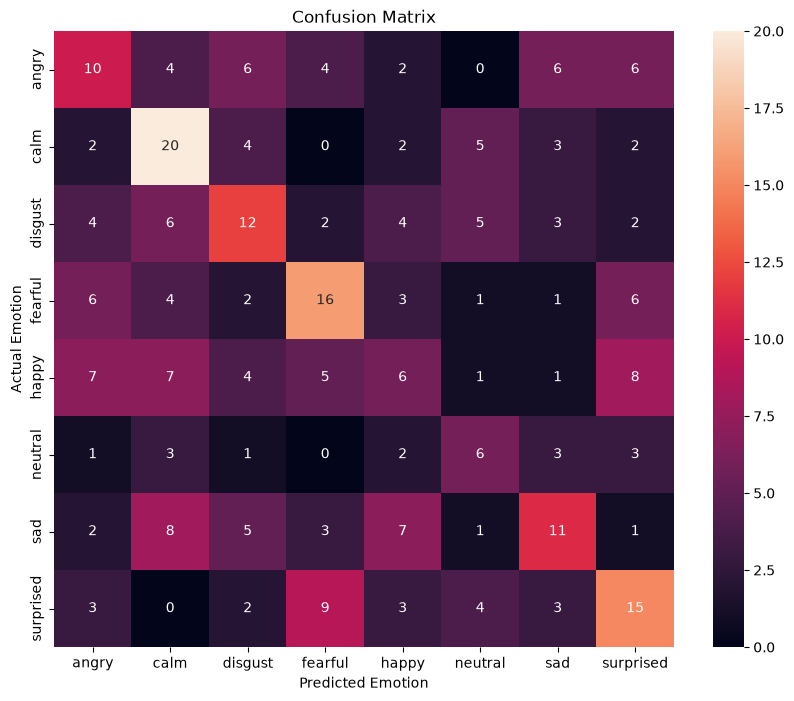

In [22]:
cm = confusion_matrix(
    y_actual,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.show()

In [23]:
model.save("speech_emotion_lstm.keras")

print("Model saved successfully!")

Model saved successfully!


In [27]:
import glob
import os

# Find all WAV files inside RAVDESS
audio_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.wav"),
    recursive=True
)

print("Number of WAV files found:", len(audio_files))

# Show first 10 files
for file in audio_files[:10]:
    print(file)

Number of WAV files found: 1440
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-01-01-01-01-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-01-01-01-02-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-01-01-02-01-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-01-01-02-02-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-02-01-01-01-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-02-01-01-02-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-02-01-02-01-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-02-01-02-02-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-02-02-01-01-01.wav
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-02-02-01-02-01.wav


In [28]:
# Select the first audio file
audio_file = audio_files[0]

print("Testing audio file:")
print(audio_file)

# Extract MFCC
mfcc = extract_mfcc(audio_file)

# Add batch dimension
mfcc = np.expand_dims(mfcc, axis=0)

# Predict
prediction = model.predict(mfcc)

# Get predicted class
predicted_index = np.argmax(prediction, axis=1)[0]

# Convert number back to emotion
predicted_emotion = label_encoder.inverse_transform(
    [predicted_index]
)[0]

print("\nPredicted Emotion:", predicted_emotion)

Testing audio file:
C:\Users\TRUPTI\Downloads\audio_speech_actors_01-24\Actor_01\03-01-01-01-01-01-01.wav
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step

Predicted Emotion: neutral
